# Расчет стоимости разработки по COCOMO II

## Цель работы
Рассчитать стоимость разработки государственной информационной системы с использованием модели COCOMO II, определить трудозатраты, длительность проекта и итоговую стоимость с учетом накладных расходов и НДС.

## Исходные данные
В работе используются следующие параметры проекта:

| Параметр | Значение |
|---|---|
| Функциональные точки (FP) | 450 |
| Язык разработки | C# |
| Коэффициент конвертации (K_p) для C# | 54 |
| Коэффициент повторного использования | 20% (0.2) |
| **Коэффициенты масштаба (SF)** | |
| PREC (Прецедентность) | 4 |
| FLEX (Гибкость) | 3 |
| RESL (Разрешение рисков) | 3 |
| TEAM (Сплоченность команды) | 4 |
| PMAT (Зрелость процессов) | 3 |
| **Множители трудоемкости (EM)** | |
| RELY (Надежность) | 1.15 |
| DATA (Размер БД) | 1.00 |
| CPLX (Сложность) | 1.15 |
| TIME (Ограничения по времени) | 1.00 |
| STOR (Ограничения по памяти) | 1.00 |
| ACAP (Способности аналитиков) | 1.15 |
| PCAP (Способности программистов) | 1.10 |
| PCON (Текучесть кадров) | 1.00 |
| APEX (Опыт в предметной области) | 1.00 |
| PEXP (Опыт в платформе) | 1.00 |
| LTEX (Опыт в языке) | 1.00 |
| TOOL (Инструменты) | 1.00 |
| SITE (География) | 1.00 |
| SCED (График) | 1.00 |
| RUSE (Повторное использование) | 1.10 |
| **Финансовые параметры** | |
| Константа A | 2.94 |
| Базовая константа B | 0.91 |
| Стоимость человеко-месяца | 220 000 руб. |
| Накладные расходы | 25% |
| НДС | 20% |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Ввод исходных данных ---

# Параметры размера
fp = 450
k_p = 54 # Коэффициент для C#
reuse_factor = 0.20

# Коэффициенты масштаба (Scale Factors)
sf_values = {
    'PREC': 4,
    'FLEX': 3,
    'RESL': 3,
    'TEAM': 4,
    'PMAT': 3
}

# Множители трудоемкости (Effort Multipliers)
em_values = {
    'RELY': 1.15, 'DATA': 1.00, 'CPLX': 1.15, 'TIME': 1.00, 'STOR': 1.00,
    'ACAP': 1.15, 'PCAP': 1.10, 'PCON': 1.00, 'APEX': 1.00, 'PEXP': 1.00,
    'LTEX': 1.00, 'TOOL': 1.00, 'SITE': 1.00, 'SCED': 1.00, 'RUSE': 1.10
}

# Финансовые и калибровочные параметры
A = 2.94
B_base = 0.91
cost_per_pm = 220_000
overhead_rate = 0.25
vat_rate = 0.20

print("Исходные данные загружены.")

Исходные данные загружены.


## Часть 1. Расчет размера системы (KLOC)

Размер программного обеспечения в тысячах строк кода (KLOC) рассчитывается на основе функциональных точек (FP) с учетом коэффициента конвертации для языка (K_p) и коэффициента повторного использования.

**Формула:**
$$KLOC = \frac{FP \times K_p}{1000} \times (1 - \text{Коэффициент\_повторного\_использования})$$


In [2]:
# 1.1. Расчет KLOC
kloc_base = (fp * k_p) / 1000
kloc_effective = kloc_base * (1 - reuse_factor)

print(f"Базовый размер (без учета повторного использования): {kloc_base:.2f} KLOC")
print(f"Эффективный размер (с учетом повторного использования): {kloc_effective:.2f} KLOC")

Базовый размер (без учета повторного использования): 24.30 KLOC
Эффективный размер (с учетом повторного использования): 19.44 KLOC


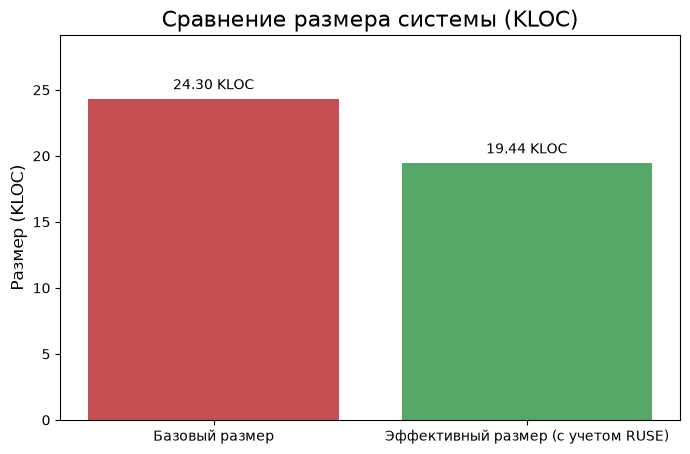

In [10]:
# Сравнение базового и эффективного размера
plt.figure(figsize=(8, 5))
bars = plt.bar(['Базовый размер', 'Эффективный размер (с учетом RUSE)'], 
               [kloc_base, kloc_effective], 
               color=['#C44E52', '#55A868'])
plt.title('Сравнение размера системы (KLOC)', fontsize=16)
plt.ylabel('Размер (KLOC)', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f} KLOC', ha='center', va='bottom')

plt.ylim(0, kloc_base * 1.2)
plt.show()

## Часть 2. Расчет трудозатрат (Effort)

Трудозатраты в человеко-месяцах (PM) рассчитываются по формуле COCOMO II.

**Формула:**
$$\text{Effort} = A \times (\text{KLOC})^B \times \prod EM_i$$

Где:
-   A = 2.94 калибровочная константа
-   B = B_{\text{base}} + 0.01 \times \sum SF_j\) коэффициент масштаба
-   EM_i — произведение всех множителей трудоемкости.

**Расчет:**

1.  **Расчет коэффициента масштаба B:**
    $$\sum SF_j = 4 + 3 + 3 + 4 + 3 = 17$$
    $$B = 0.91 + 0.01 \times 17 = 0.91 + 0.17 = 1.08$$

2.  **Расчет произведения множителей (EM):**
    $$\prod EM_i = 1.15 \times 1.15 \times 1.15 \times 1.10 \times 1.10 = 1.840$$

3.  **Расчет трудозатрат:**
    $$\text{Effort} = 2.94 \times (19.44)^{1.08} \times 1.840$$
    $$\text{Effort} = 2.94 \times 24.66 \times 1.840 \approx 133.4 \text{ чел.-мес.}$$

In [3]:
# 2.1. Расчет коэффициента масштаба B
sum_sf = sum(sf_values.values())
B = B_base + 0.01 * sum_sf
print(f"Сумма коэффициентов масштаба (ΣSF): {sum_sf}")
print(f"Коэффициент масштаба B: {B:.2f}")

# 2.2. Расчет произведения множителей трудоемкости
em_product = np.prod(list(em_values.values()))
print(f"Произведение множителей трудоемкости (ΠEM): {em_product:.3f}")

# 2.3. Расчет трудозатрат
effort = A * (kloc_effective ** B) * em_product
print(f"\nТрудозатраты (Effort): {effort:.1f} чел.-мес.")

Сумма коэффициентов масштаба (ΣSF): 17
Коэффициент масштаба B: 1.08
Произведение множителей трудоемкости (ΠEM): 1.840

Трудозатраты (Effort): 133.4 чел.-мес.


## Часть 3. Расчет длительности (TDEV)

Длительность проекта в месяцах рассчитывается по формуле:

**Формула:**
$$\text{TDEV} = C \times (\text{Effort})^D$$

Для COCOMO II (Post-Architecture) используются константы \(C = 2.5\) и \(D = 0.35\).

In [4]:
# 3.1. Расчет длительности
C = 2.5
D = 0.35
tdev = C * (effort ** D)

print(f"Длительность разработки (TDEV): {tdev:.1f} мес.")

Длительность разработки (TDEV): 13.9 мес.


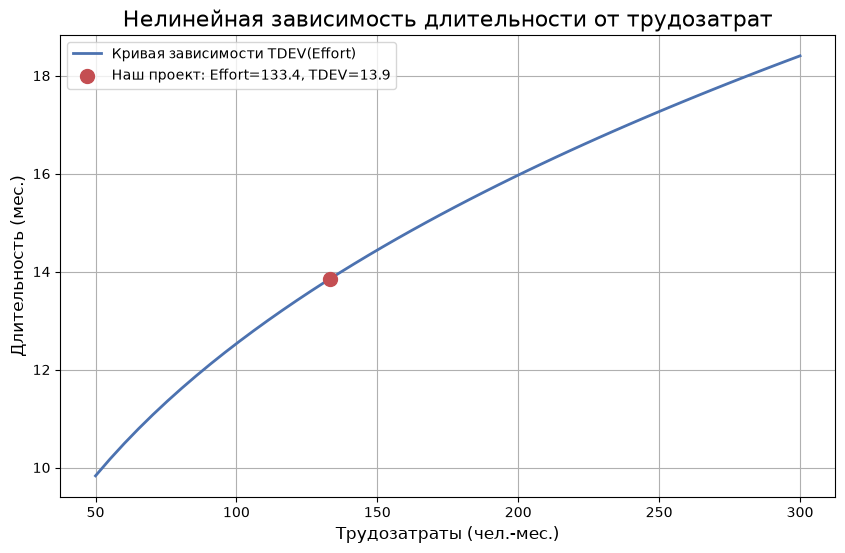

In [16]:
# График зависимости длительности от трудозатрат
# Создадим диапазон значений трудозатрат для построения кривой
effort_range = np.linspace(50, 300, 50)
tdev_range = C * (effort_range ** D)

plt.figure(figsize=(10, 6))
plt.plot(effort_range, tdev_range, label='Кривая зависимости TDEV(Effort)', color='#4C72B0', linewidth=2)

# Отметим нашу точку
plt.scatter(effort, tdev, color='#C44E52', s=100, zorder=5, label=f'Наш проект: Effort={effort:.1f}, TDEV={tdev:.1f}')

plt.title('Нелинейная зависимость длительности от трудозатрат', fontsize=16)
plt.xlabel('Трудозатраты (чел.-мес.)', fontsize=12)
plt.ylabel('Длительность (мес.)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

## Часть 4. Расчет стоимости

Итоговая стоимость проекта складывается из прямых затрат на разработку, накладных расходов и НДС.

1.  **Прямые затраты на разработку:**
    $$\text{Cost}_{\text{direct}} = \text{Effort} \times \text{Стоимость чел.-мес.}$$
    $$\text{Cost}_{\text{direct}} = 133.4 \times 220\,000 = 29\,348\,000 \text{ руб.}$$

2.  **Накладные расходы (25%):**
    $$\text{Overhead} = 29\,338\,700 \times 0.25 = 7\,334\,675 \text{ руб.}$$

3.  **Полная стоимость без НДС:**
    $$\text{Cost}_{\text{без НДС}} = 29\,338\,700 + 7\,334\,675 = 36\,673\,375 \text{ руб.}$$

4.  **Стоимость с НДС (20%):**
    $$\text{Cost}_{\text{с НДС}} = 36\,673\,375 \times 1.20 = 44\,008\,050 \text{ руб.}$$

In [5]:
# 4.1. Прямые затраты
direct_cost = effort * cost_per_pm
print(f"Прямые затраты на разработку: {direct_cost:,.0f} руб.")

# 4.2. Накладные расходы
overhead_cost = direct_cost * overhead_rate
print(f"Накладные расходы: {overhead_cost:,.0f} руб.")

# 4.3. Полная стоимость без НДС
total_cost_no_vat = direct_cost + overhead_cost
print(f"Полная стоимость без НДС: {total_cost_no_vat:,.0f} руб.")

# 4.4. Стоимость с НДС
total_cost_with_vat = total_cost_no_vat * (1 + vat_rate)
print(f"Стоимость с НДС: {total_cost_with_vat:,.0f} руб.")

Прямые затраты на разработку: 29,338,700 руб.
Накладные расходы: 7,334,675 руб.
Полная стоимость без НДС: 36,673,375 руб.
Стоимость с НДС: 44,008,050 руб.


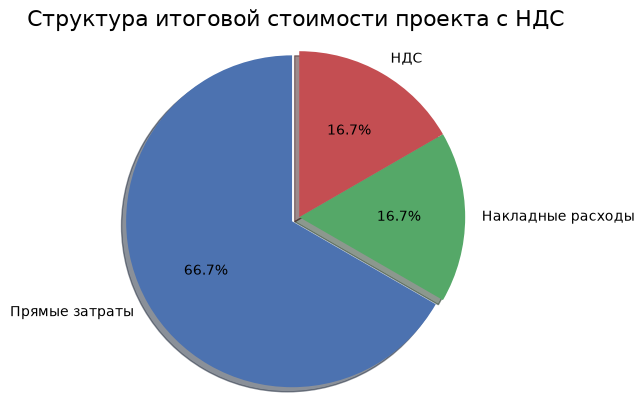

In [15]:
# Круговая диаграмма структуры затрат
vat_amount = total_cost_with_vat - total_cost_no_vat
labels = ['Прямые затраты', 'Накладные расходы', 'НДС']
sizes = [direct_cost, overhead_cost, vat_amount]
colors = ['#4C72B0', '#55A868', '#C44E52']
explode = (0.05, 0, 0)  # Выделим сектор прямых затрат
fig1, ax1 = plt.subplots()
ax1.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=90)
ax1.axis('equal')  # Равные оси для круглой диаграммы
plt.title('Структура итоговой стоимости проекта с НДС', fontsize=16)
plt.show()

In [14]:
# 5.1. Сводная таблица результатов
summary_data = {
    'Параметр': [
        'Эффективный размер (KLOC)',
        'Трудозатраты (чел.-мес.)',
        'Длительность (мес.)',
        'Прямые затраты (руб.)',
        'Накладные расходы (руб.)',
        'Полная стоимость без НДС (руб.)',
        'Стоимость с НДС (руб.)'
    ],
    'Значение': [
        f'{kloc_effective:.2f}',
        f'{effort:.1f}',
        f'{tdev:.1f}',
        f'{direct_cost:,.0f}',
        f'{overhead_cost:,.0f}',
        f'{total_cost_no_vat:,.0f}',
        f'{total_cost_with_vat:,.0f}'
    ]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Параметр,Значение
0,Эффективный размер (KLOC),19.44
1,Трудозатраты (чел.-мес.),133.4
2,Длительность (мес.),13.9
3,Прямые затраты (руб.),"29,338,700"
4,Накладные расходы (руб.),"7,334,675"
5,Полная стоимость без НДС (руб.),"36,673,375"
6,Стоимость с НДС (руб.),"44,008,050"


### Вывод

В результате расчета по модели COCOMO II была определена стоимость разработки государственной информационной системы "Единый портал поддержки предпринимателей". Итоговая стоимость проекта с учетом всех затрат и НДС составляет **≈ 44,0 млн рублей**. Полученные трудозатраты в 133,4 человеко-месяца и длительность в 13,9 месяцев являются реалистичными для проекта такого масштаба.